In [3]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# 1. Configuration & Constants
# ----------------------------
# Setting style for professional plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Define paths using pathlib for OS agnosticism (works perfectly on Windows/Linux)
BASE_DIR = Path('..')
DATA_DIR = BASE_DIR / 'data'
IMAGE_DIR = DATA_DIR / 'all_images'
METADATA_PATH = DATA_DIR / 'HAM10000_metadata.csv'

# Quick sanity check to ensure we are in the right directory
if not METADATA_PATH.exists():
    raise FileNotFoundError(f"Metadata not found at {METADATA_PATH}. Check your directory structure.")

print(f"Project Root: {BASE_DIR.resolve()}")
print(f"Images Directory: {IMAGE_DIR.resolve()}")

Project Root: C:\Users\zmoy0\Desktop\personal_projects\derma-scan
Images Directory: C:\Users\zmoy0\Desktop\personal_projects\derma-scan\data\all_images


In [4]:
# 2. Loading Data
# ---------------

# Load metadata
df = pd.read_csv(METADATA_PATH)

# Dictionary to map technical abbreviations to full medical names
# Source: HAM10000 dataset documentation
lesion_type_dict = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}

# Create a readable 'cell_type' column for visualizations
df['cell_type'] = df['dx'].map(lesion_type_dict)

# Construct the full file path for each image
# We assume images are .jpg. Using a lambda function is cleaner here.
df['path'] = df['image_id'].apply(lambda x: IMAGE_DIR / f"{x}.jpg")

# Verify that the mapped paths actually exist (sanity check)
# We check the first image just to be sure
first_img_path = df['path'].iloc[0]
if not first_img_path.exists():
    print(f"WARNING: The file {first_img_path} does not exist. Check if you unzipped images into 'data/all_images'.")

print(f"Dataset loaded successfully. Total samples: {df.shape[0]}")
df.head()

Dataset loaded successfully. Total samples: 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization,cell_type,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0027419.jpg
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0025030.jpg
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0026769.jpg
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,Benign keratosis-like lesions,..\data\all_images\ISIC_0025661.jpg
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,Benign keratosis-like lesions,..\data\all_images\ISIC_0031633.jpg


In [5]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split

# ==========================================
# 1. Configuration & Constants
# ==========================================
# Standard ImageNet statistics (Mean and Std Dev)
# REQUIRED for Transfer Learning with ResNet/EfficientNet
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

# Image size expected by the model (224x224 is standard for ResNet)
IMG_SIZE = 224
BATCH_SIZE = 32

# ==========================================
# 2. Data Augmentation Strategy
# ==========================================
def get_transforms(phase='train'):
    """
    Returns the transformation pipeline for training or validation.
    
    Why these choices?
    - Resize: Models need fixed input dimensions.
    - RandomHorizontal/VerticalFlip: Skin lesions have no orientation context (unlike a face or car).
      A rotated melanoma is still a melanoma. This effectively quadruples our dataset size.
    - RandomRotation: Further simulates different camera angles.
    - ColorJitter: Simulates different lighting conditions in clinics 
      (but kept subtle to preserve color diagnostics like redness).
    - Normalization: Aligns image math with the pre-trained model weights.
    """
    if phase == 'train':
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),
            transforms.RandomRotation(20),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
            transforms.ToTensor(),
            transforms.Normalize(NORM_MEAN, NORM_STD)
        ])
    else:
        # For Validation/Test: No random noise, just resizing and normalization
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(NORM_MEAN, NORM_STD)
        ])

# ==========================================
# 3. Custom Dataset Class
# ==========================================
class SkinCancerDataset(Dataset):
    """
    Custom PyTorch Dataset for HAM10000.
    """
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform
        
        # Creating a mapping from string labels to integers
        # This is essential for the CrossEntropyLoss function
        self.label_map = {
            'nv': 0, 'mel': 1, 'bkl': 2, 'bcc': 3, 
            'akiec': 4, 'vasc': 5, 'df': 6
        }

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # 1. Get image path and label
        img_path = self.df.iloc[idx]['path']
        label_str = self.df.iloc[idx]['dx']
        
        # 2. Load Image
        # .convert('RGB') is crucial because some medical images might be RGBA or Grayscale
        image = Image.open(img_path).convert('RGB')
        
        # 3. Apply Transformations (Augmentation)
        if self.transform:
            image = self.transform(image)
            
        # 4. Convert label to integer
        label = torch.tensor(self.label_map[label_str], dtype=torch.long)
        
        return image, label

In [6]:
# ==========================================
# 4. Splitting Data (Stratified)
# ==========================================

# Assuming 'df' is loaded from your previous step (EDA)
# If not, reload it here:
# df = pd.read_csv('../data/HAM10000_metadata.csv')
# df['path'] = df['image_id'].apply(lambda x: f"../data/all_images/{x}.jpg")

# We use the 'dx' column (diagnosis) for stratification
train_df, val_df = train_test_split(
    df, 
    test_size=0.2, 
    random_state=42, 
    stratify=df['dx'] # <--- KEY: Keeps the same % of cancer in train and val
)

print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")

# Verify Stratification
print("\n--- Validation Set Distribution (Check for balance) ---")
print(val_df['dx'].value_counts(normalize=True)) 
# You should see ~11% for 'mel', same as the original dataset.

# ==========================================
# 5. Creating Data Loaders
# ==========================================

train_dataset = SkinCancerDataset(train_df, transform=get_transforms('train'))
val_dataset = SkinCancerDataset(val_df, transform=get_transforms('val'))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0) # num_workers=0 for Windows compatibility
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("\nData Loaders ready.")

Training samples: 8012
Validation samples: 2003

--- Validation Set Distribution (Check for balance) ---
dx
nv       0.669496
mel      0.111333
bkl      0.109835
bcc      0.051423
akiec    0.032451
vasc     0.013979
df       0.011483
Name: proportion, dtype: float64

Data Loaders ready.


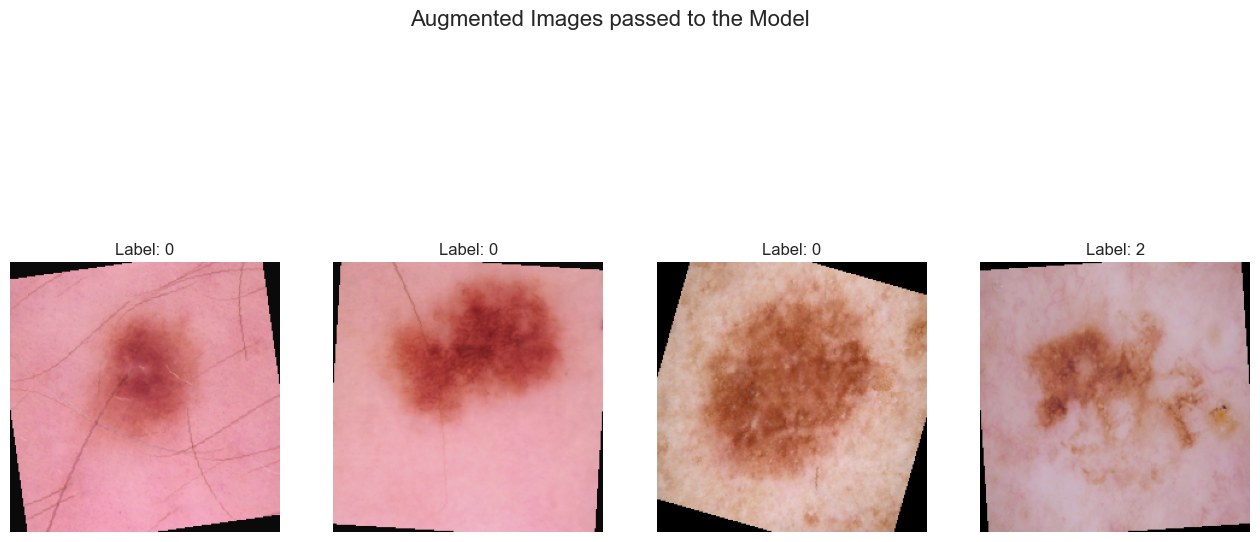

In [7]:
# ==========================================
# 6. Visualization of Augmented Batch
# ==========================================
def show_batch(loader):
    """
    Helper function to visualize a batch of transformed images.
    Since images are normalized, we need to un-normalize them for display.
    """
    images, labels = next(iter(loader))
    
    plt.figure(figsize=(16, 8))
    
    # Grid of 4 images
    for i in range(4):
        ax = plt.subplot(1, 4, i + 1)
        
        # Move tensor to numpy
        img = images[i].numpy().transpose((1, 2, 0))
        
        # Un-normalize for visualization: img = img * std + mean
        mean = np.array(NORM_MEAN)
        std = np.array(NORM_STD)
        img = std * img + mean
        img = np.clip(img, 0, 1) # Ensure values are between 0 and 1
        
        plt.imshow(img)
        plt.title(f"Label: {labels[i].item()}")
        plt.axis("off")
        
    plt.suptitle("Augmented Images passed to the Model", fontsize=16)
    plt.show()

# Visualize
show_batch(train_loader)